# JTWPA gain with and without reflectionless filtering

I compare one JosephsonCircuits JTWPA under three termination models: ideal 50-ohm loads, nonideal circulators, and a reflectionless-filter/circulator cascade. The circuit follows the package example based on Macklin et al.; the comparison is motivated by Kedziora et al.

The recorded circulator-only run contains a non-convergence warning, so that gain trace is provisional. No fresh harmonic-balance rerun is claimed. The separate Python script checks the sampled surrogate-network parameters only.


## Method

Keep the nonlinear amplifier circuit fixed and change only its external frequency-dependent impedances. Two-port network reflection is reduced to the input impedance used at each port.


In [1]:
# Optional one-time installation.
# Uncomment and run this cell once if the packages are not installed.
#
# import Pkg
# Pkg.add("JosephsonCircuits")
# Pkg.add("Plots")

using JosephsonCircuits
using Plots

println("Julia threads: ", Threads.nthreads())


Julia threads: 1


## 1. JTWPA circuit: Macklin et al. parameters

These are the parameters used in the official `JosephsonCircuits.jl` JTWPA example:

- `Nj = 2048` junction cells
- `pmrpitch = 4`
- `Ic = 3.4 µA`
- `Cg = 45 fF`
- `Cc = 30 fF`
- `Cr = 2.8153 pF`
- `Lr = 170 pH`
- `Cj = 55 fF`
- pump frequency = `7.12 GHz`
- pump current = `1.85 µA`

The unit-cell topology below intentionally follows the package example rather than introducing an object-oriented circuit abstraction.


In [2]:
# JTWPA parameters
@variables Rleft Rright Cg Lj Cj Cc Cr Lr
@variables w

Nj = 2048
pmrpitch = 4

R0 = 50.0

Cg_value = 45.0e-15
Lj_value = IctoLj(3.4e-6)
Cj_value = 55.0e-15
Cc_value = 30.0e-15
Cr_value = 2.8153e-12
Lr_value = 1.70e-10

println("Lj = ", Lj_value*1e12, " pH")
println("Ic = 3.4 uA")


Lj = 96.79587529411765 pH
Ic = 3.4 uA


### Netlist builder

The builder below is deliberately close to the official JTWPA example. It returns the tuple-based circuit expected by `hbsolve`.

The only quantities that change between the three configurations are `Rleft` and `Rright`, which can be either 50 Ω or symbolic frequency-dependent impedances.


In [3]:
function build_jtwpa()
    circuit = Tuple{String,String,String,Num}[]

    # Input port and its reference impedance
    push!(circuit, ("P1_0", "1", "0", 1))
    push!(circuit, ("R1_0", "1", "0", Rleft))

    # First half shunt capacitance
    push!(circuit, ("C1_0", "1", "0", Cg/2))

    # First junction cell
    push!(circuit, ("Lj1_2", "1", "2", Lj))
    push!(circuit, ("C1_2", "1", "2", Cj))

    j = 2

    for i = 2:Nj-1
        if mod(i, pmrpitch) == pmrpitch ÷ 2
            # Modified junction cell at the phase-matching resonator position
            push!(circuit, ("C$(j)_0", "$(j)", "0", Cg - Cc))
            push!(circuit, ("Lj$(j)_$(j+2)", "$(j)", "$(j+2)", Lj))
            push!(circuit, ("C$(j)_$(j+2)", "$(j)", "$(j+2)", Cj))

            # Phase-matching resonator
            push!(circuit, ("C$(j)_$(j+1)", "$(j)", "$(j+1)", Cc))
            push!(circuit, ("C$(j+1)_0", "$(j+1)", "0", Cr))
            push!(circuit, ("L$(j+1)_0", "$(j+1)", "0", Lr))

            j += 1
        else
            push!(circuit, ("C$(j)_0", "$(j)", "0", Cg))
            push!(circuit, ("Lj$(j)_$(j+1)", "$(j)", "$(j+1)", Lj))
            push!(circuit, ("C$(j)_$(j+1)", "$(j)", "$(j+1)", Cj))
        end

        j += 1
    end

    # Last half shunt capacitance, output termination and port
    push!(circuit, ("C$(j)_0", "$(j)", "0", Cg/2))
    push!(circuit, ("R$(j)_0", "$(j)", "0", Rright))
    push!(circuit, ("P$(j)_0", "$(j)", "0", 2))

    return circuit
end

circuit_template = build_jtwpa()
println("Number of netlist elements: ", length(circuit_template))


Number of netlist elements: 7682


## 2. Representing a measured 2-port termination as an impedance

Suppose an external 2-port network is terminated in 50 Ω at its far end. Its input reflection coefficient is

\[
\Gamma_{in}
=
S_{11}
+
\frac{S_{12}S_{21}\Gamma_L}
{1-S_{22}\Gamma_L},
\qquad \Gamma_L=0
\]

for a matched load, so for the simplest case `Γin = S11`.

The corresponding input impedance is

\[
Z_{in}(\omega)
=
Z_0\frac{1+\Gamma_{in}(\omega)}
{1-\Gamma_{in}(\omega)}.
\]

This is the quantity we place in the JTWPA netlist as a frequency-dependent `R` element.

This is also the route recommended by the JosephsonCircuits maintainer for including arbitrary S-parameter environments in an HB simulation: convert the network to equivalent frequency-dependent impedances, register the functions with `@register_symbolic`, and pass the symbolic frequency to `hbsolve`.


In [4]:
# Helper: convert a one-port reflection coefficient into input impedance.
function gamma_to_z(gamma, z0)
    return z0 * (1 + gamma) / (1 - gamma)
end

# --- Surrogate circulator model ---
#
# This is NOT the measured circulator from the paper.
# It is deliberately simple: good match in-band and increasingly reflective
# outside the nominal 4-10 GHz operating band.

function gamma_circulator_positive(wrad)
    f = wrad / (2*pi)

    f_lo = 4.0e9
    f_hi = 10.0e9
    fc = sqrt(f_lo*f_hi)
    bw = f_hi - f_lo

    x = (f - fc)/(bw/2)

    # In-band return loss ≈ 20 dB; out-of-band reflection rises smoothly.
    window = abs(x) <= 1 ? 1.0 : exp(-((abs(x)-1)*2.2)^2)
    RL_dB = 20.0*window + 1.0*(1.0-window)

    # A modest electrical delay gives the reflection a frequency-dependent phase.
    phase_delay = 0.35e-9

    return 10.0^(-RL_dB/20) * exp(1im*2*pi*f*phase_delay)
end

function Z_circulator(wrad)
    if wrad < 0
        return conj(Z_circulator(-wrad))
    end
    gamma = gamma_circulator_positive(wrad)
    return gamma_to_z(gamma, R0)
end

@register_symbolic Z_circulator(w)


In [5]:
# --- Surrogate reflectionless-filter model ---
#
# The actual paper uses a measured/nonideal reflectionless filter.
# Its exact measured Touchstone data are not contained in the manuscript.
#
# We model the key behavior needed for Fig. 1:
#   * low reflection across the useful band
#   * low insertion loss in the passband
#   * strong attenuation in the out-of-band region
#
# The filter is represented here by its 2-port S parameters, then reduced
# to the input reflection coefficient of "filter + circulator".

function reflectionless_filter_S_positive(wrad)
    f = wrad / (2*pi)

    f_low = 3.2e9
    f_high = 11.8e9

    # Smooth passband envelope.
    n = 8.0
    low_edge = 1.0 / (1.0 + (f_low/max(f, 1.0))^n)
    high_edge = 1.0 / (1.0 + (f/max(f_high, 1.0))^n)
    transmission_envelope = sqrt(low_edge * high_edge)

    insertion_loss_dB = 0.75
    delay = 80e-12

    S21 = 10.0^(-insertion_loss_dB/20) *
          transmission_envelope *
          exp(-1im*2*pi*f*delay)

    # Reflectionless behavior: keep S11/S22 small over the full band.
    reflection_dB = -28.0
    S11 = 10.0^(reflection_dB/20) *
          exp(1im*(2*pi*f*35e-12 + 0.3))

    S22 = S11 * exp(1im*0.2)

    return ComplexF64[
        S11  S21;
        S21  S22
    ]
end

function reflectionless_filter_S(wrad)
    if wrad < 0
        return conj.(reflectionless_filter_S(-wrad))
    end
    return reflectionless_filter_S_positive(wrad)
end

# Input reflection of a 2-port network A terminated by a one-port load ΓL.
function input_gamma_from_S(SA, gammaL)
    return SA[1,1] +
           SA[1,2]*SA[2,1]*gammaL /
           (1 - SA[2,2]*gammaL)
end

# Configuration (c): reflectionless filter followed by the circulator.
function gamma_filter_plus_circulator_positive(wrad)
    Sf = reflectionless_filter_S_positive(wrad)
    gammaL = gamma_circulator_positive(wrad)
    return input_gamma_from_S(Sf, gammaL)
end

function Z_filter(wrad)
    if wrad < 0
        return conj(Z_filter(-wrad))
    end
    gamma = reflectionless_filter_S_positive(wrad)[1,1]
    return gamma_to_z(gamma, R0)
end

function Z_filter_plus_circulator(wrad)
    if wrad < 0
        return conj(Z_filter_plus_circulator(-wrad))
    end
    gamma = gamma_filter_plus_circulator_positive(wrad)
    return gamma_to_z(gamma, R0)
end

@register_symbolic Z_filter(w)
@register_symbolic Z_filter_plus_circulator(w)


## 3. Sanity-check the termination models before running HB

This is a cheap diagnostic. It is useful because the HB solver will evaluate the impedance at positive **and negative** frequencies when idler modes are present.

The impedance must remain passive here, i.e. `real(Z) > 0`. The negative-frequency branch is explicitly defined as the complex conjugate of the positive-frequency branch.


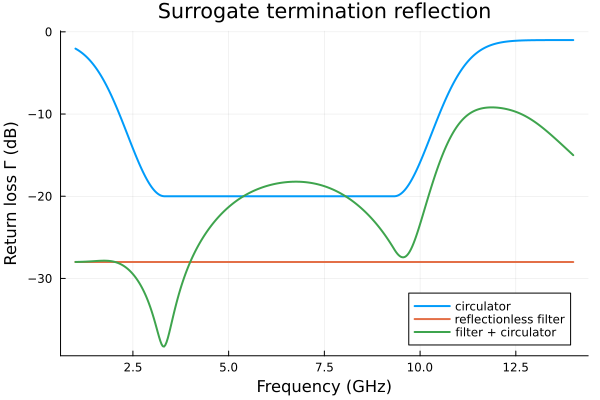

In [6]:
f_preview = collect(range(1.0e9, 14.0e9, length=400))
w_preview = 2*pi .* f_preview

Zcirc_preview = [Z_circulator(wi) for wi in w_preview]
Zfilt_preview = [Z_filter(wi) for wi in w_preview]
Zfc_preview = [Z_filter_plus_circulator(wi) for wi in w_preview]

@assert all(real.(Zcirc_preview) .> 0)
@assert all(real.(Zfilt_preview) .> 0)
@assert all(real.(Zfc_preview) .> 0)

p = plot(
    f_preview/1e9,
    20 .* log10.(abs.((Zcirc_preview .- R0) ./ (Zcirc_preview .+ R0))),
    label="circulator",
    xlabel="Frequency (GHz)",
    ylabel="Return loss Γ (dB)",
    title="Surrogate termination reflection",
    linewidth=2,
)
plot!(
    p,
    f_preview/1e9,
    20 .* log10.(abs.((Zfilt_preview .- R0) ./ (Zfilt_preview .+ R0))),
    label="reflectionless filter",
    linewidth=2,
)
plot!(
    p,
    f_preview/1e9,
    20 .* log10.(abs.((Zfc_preview .- R0) ./ (Zfc_preview .+ R0))),
    label="filter + circulator",
    linewidth=2,
)


## 4. Build the three JosephsonCircuits netlists

We use the **same nonlinear JTWPA** in all three cases.

Only the impedance environment changes:

- **(a)** `Rleft = 50 Ω`, `Rright = 50 Ω`
- **(b)** `Rleft = Z_circulator(w)`, `Rright = Z_circulator(w)`
- **(c)** `Rleft = Z_filter(w)`, `Rright = Z_filter_plus_circulator(w)`

This is the key correction to the previous notebook: there is no `Port(...)`, no `Circuit(...)`, no `Capacitor(...)`, and no `ScatteringParameters(...)` object inside the HB netlist.


In [7]:
circuit_a = build_jtwpa()
circuit_b = build_jtwpa()
circuit_c = build_jtwpa()

# Numeric component values for the common JTWPA.
common_defs = Dict(
    Lj => Lj_value,
    Cg => Cg_value,
    Cc => Cc_value,
    Cr => Cr_value,
    Lr => Lr_value,
    Cj => Cj_value,
)

defs_a = merge(common_defs, Dict(
    Rleft => R0,
    Rright => R0,
))

defs_b = merge(common_defs, Dict(
    Rleft => Z_circulator(w),
    Rright => Z_circulator(w),
))

defs_c = merge(common_defs, Dict(
    Rleft => Z_filter(w),
    Rright => Z_filter_plus_circulator(w),
))

println("Configuration (a) elements: ", length(circuit_a))
println("Configuration (b) elements: ", length(circuit_b))
println("Configuration (c) elements: ", length(circuit_c))


Configuration (a) elements: 7682
Configuration (b) elements: 7682
Configuration (c) elements: 7682


## 5. Harmonic-balance settings

These values follow the official JTWPA example in `JosephsonCircuits.jl`.

For a first run, keep the 0.1-GHz frequency spacing. Once the simulation works, the spacing can be reduced to 0.05 GHz for a smoother figure.

The solver is run **sequentially** rather than storing all three very large HB solutions simultaneously. This reduces peak memory usage on a workstation.


In [20]:
# Signal-frequency sweep
signal_frequency = collect(1.0:0.01:14.0) * 1e9
ws = 2*pi .* signal_frequency

# Strong pump
pump_frequency = 7.12e9
wp = (2*pi*pump_frequency,)

Ip = 1.85e-6
sources = [(mode=(1,), port=1, current=Ip)]

# Same truncation as the official JTWPA example.
Npumpharmonics = (20,)
Nmodulationharmonics = (10,)

println("Signal points: ", length(ws))
println("Pump frequency: ", pump_frequency/1e9, " GHz")
println("Pump current: ", Ip*1e6, " uA")


Signal points: 1301
Pump frequency: 7.12 GHz
Pump current: 1.85 uA


## 6. Configuration (a): ideal 50-Ω terminations

This should reproduce the normal JosephsonCircuits JTWPA gain curve and serves as the first validation step.

**Run this cell before attempting (b) or (c).**


In [21]:
@time sol_a = hbsolve(
    ws, wp, sources,
    Nmodulationharmonics, Npumpharmonics,
    circuit_a, defs_a;
    returnS = true,
    returnSnoise = false,
    returnQE = false,
    returnCM = false,
)


 78.463211 seconds (295.41 k allocations: 1.980 GiB, 2.06% gc time)


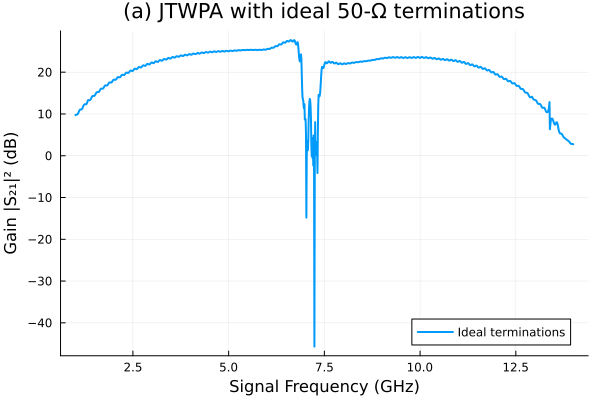

In [22]:
S21_a = sol_a.linearized.S(
    outputmode=(0,),
    outputport=2,
    inputmode=(0,),
    inputport=1,
    freqindex=:,
)

gain_a = 10 .* log10.(abs2.(S21_a))

plot(
    sol_a.linearized.w/(2*pi*1e9),
    gain_a,
    xlabel="Signal Frequency (GHz)",
    ylabel="Gain |S₂₁|² (dB)",
    title="(a) JTWPA with ideal 50-Ω terminations",
    label="Ideal terminations",
    linewidth=2,
    legend=:bottomright,
)


## 7. Configuration (b): nonideal circulator termination

Here the circulator is not inserted as an abstract S-parameter object.

Instead, its measured/surrogate input reflection is converted into `Z_circulator(w)`, which appears as the port termination resistor in the HB circuit.

This lets the nonlinear pump solution and the small-signal linearization both "see" the frequency-dependent impedance.


In [23]:
@time sol_b = hbsolve(
    ws, wp, sources,
    Nmodulationharmonics, Npumpharmonics,
    circuit_b, defs_b;
    symfreqvar = w,
    returnS = true,
    returnSnoise = false,
    returnQE = false,
    returnCM = false,
)


norm(F)/norm(x): 0.016941805439842982
Infinity norm: 0.045221552788420015


┌ Warning: Solver did not converge after maximum iterations of 1000.
└ @ JosephsonCircuits C:\Users\Mukul\.julia\packages\JosephsonCircuits\6Je0E\src\nlsolve.jl:370


145.253640 seconds (42.20 M allocations: 10.892 GiB, 3.12% gc time)


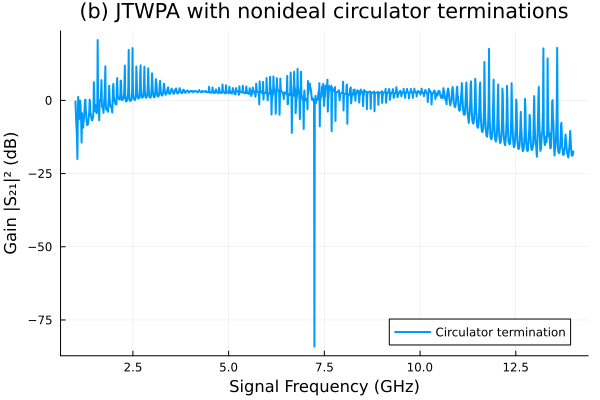

In [24]:
S21_b = sol_b.linearized.S(
    outputmode=(0,),
    outputport=2,
    inputmode=(0,),
    inputport=1,
    freqindex=:,
)

gain_b = 10 .* log10.(abs2.(S21_b))

plot(
    sol_b.linearized.w/(2*pi*1e9),
    gain_b,
    xlabel="Signal Frequency (GHz)",
    ylabel="Gain |S₂₁|² (dB)",
    title="(b) JTWPA with nonideal circulator terminations",
    label="Circulator termination",
    linewidth=2,
    legend=:bottomright,
)


## 8. Configuration (c): reflectionless filter + circulator

The right-side termination is the cascade

```text
TWPA → reflectionless filter → circulator → 50 Ω
```

and the left-side termination is the reflectionless filter terminated by a 50-Ω source.

The cascade is reduced to a single input reflection coefficient before entering the HB solver.


In [25]:
@time sol_c = hbsolve(
    ws, wp, sources,
    Nmodulationharmonics, Npumpharmonics,
    circuit_c, defs_c;
    symfreqvar = w,
    returnS = true,
    returnSnoise = false,
    returnQE = false,
    returnCM = false,
)


 94.083588 seconds (44.77 M allocations: 3.892 GiB, 2.05% gc time)


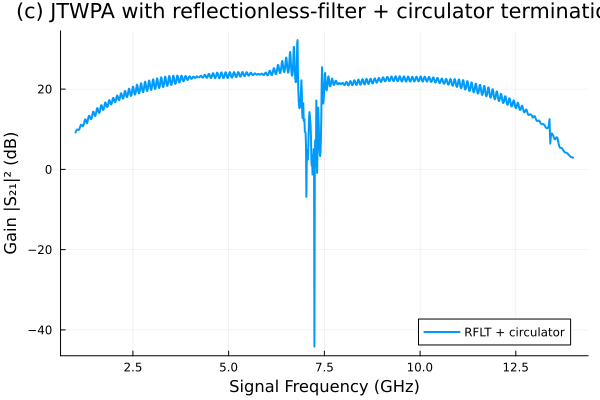

In [26]:
S21_c = sol_c.linearized.S(
    outputmode=(0,),
    outputport=2,
    inputmode=(0,),
    inputport=1,
    freqindex=:,
)

gain_c = 10 .* log10.(abs2.(S21_c))

plot(
    sol_c.linearized.w/(2*pi*1e9),
    gain_c,
    xlabel="Signal Frequency (GHz)",
    ylabel="Gain |S₂₁|² (dB)",
    title="(c) JTWPA with reflectionless-filter + circulator terminations",
    label="RFLT + circulator",
    linewidth=2,
    legend=:bottomright,
)


## 9. Recreate the three-panel comparison in one plot

The qualitative target is the same as Fig. 1 of the paper: ideal matched terminations give the smoothest baseline; a reflective out-of-band circulator produces strong gain ripple; adding a reflectionless filter between the TWPA and circulator suppresses the problematic reflection.

The absolute numerical agreement of (b) and (c) with the published figure is **not expected** until the actual measured S-parameter data used by the authors are supplied.


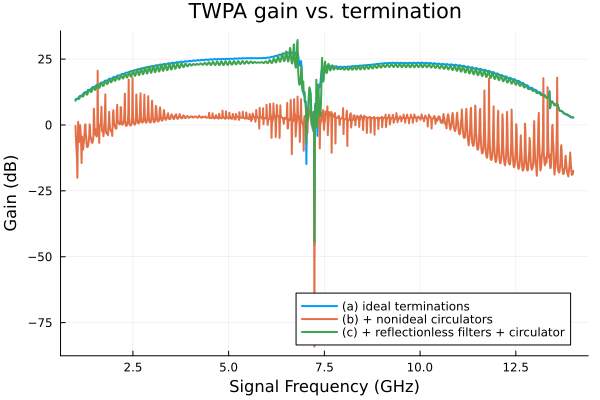

In [27]:
freq_GHz = sol_a.linearized.w/(2*pi*1e9)

p_fig1 = plot(
    freq_GHz, gain_a,
    label="(a) ideal terminations",
    xlabel="Signal Frequency (GHz)",
    ylabel="Gain (dB)",
    title="TWPA gain vs. termination",
    linewidth=2,
    legend=:bottomright,
)

plot!(p_fig1, freq_GHz, gain_b,
    label="(b) + nonideal circulators",
    linewidth=2,
)

plot!(p_fig1, freq_GHz, gain_c,
    label="(c) + reflectionless filters + circulator",
    linewidth=2,
)

p_fig1


In [28]:
savefig(p_fig1, "jtwpa_gain_vs_termination.png")

"c:\\Users\\Mukul\\Downloads\\jtwpa_gain_vs_termination.png"

## 10. Inspect the three termination reflection coefficients

This plot is useful for understanding the result.

The key quantity seen by the TWPA is not simply the insertion loss of the external component. It is the **complex impedance / reflection coefficient looking back into the external network**.

The reflectionless filter reduces the out-of-band reflection presented to the TWPA while retaining low passband insertion loss.


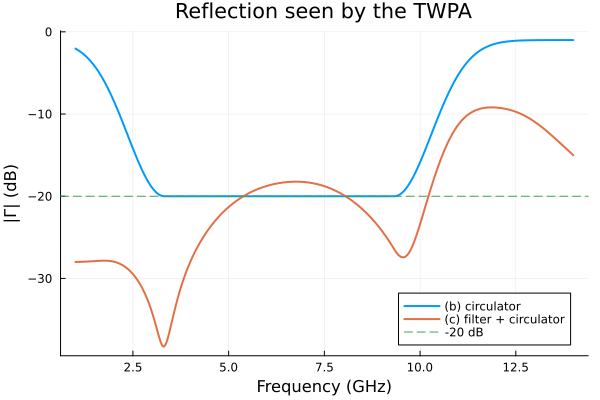

In [16]:
gamma_a = zeros(ComplexF64, length(w_preview))
gamma_b = [gamma_circulator_positive(wi) for wi in w_preview]
gamma_c = [gamma_filter_plus_circulator_positive(wi) for wi in w_preview]

plot(
    f_preview/1e9,
    20 .* log10.(max.(abs.(gamma_b), 1e-12)),
    label="(b) circulator",
    xlabel="Frequency (GHz)",
    ylabel="|Γ| (dB)",
    title="Reflection seen by the TWPA",
    linewidth=2,
)
plot!(
    f_preview/1e9,
    20 .* log10.(max.(abs.(gamma_c), 1e-12)),
    label="(c) filter + circulator",
    linewidth=2,
)
hline!([-20], label="-20 dB", linestyle=:dash)


## 11. Optional: quantum-efficiency calculation

The paper emphasizes that the reflectionless filter should improve impedance matching without introducing large passband loss.

For the three HB simulations above, QE was disabled to reduce memory consumption. If you want the JosephsonCircuits quantum-efficiency output, rerun each `hbsolve` call with:

```julia
returnQE = true
returnCM = true
```

and then use:

```julia
sol.linearized.QE(...)
sol.linearized.QEideal(...)
```

The paper's central point is that the filter's low passband insertion loss should preserve quantum efficiency while its broadband absorption prevents unwanted reflected power from the external chain.


## 12. Replacing the surrogate model with real measured data

The manuscript states that the authors used **measured isolator S-parameters** for Fig. 1(b), and repeated the simulation with a **nonideal reflectionless filter plus the measured isolator** for Fig. 1(c). The paper itself does not include the Touchstone files.

When you obtain the actual `.s2p` files, the replacement workflow is:

1. Load the measured 2-port S-parameters.
2. Interpolate them as a function of frequency.
3. Terminate the external network in 50 Ω.
4. Calculate its input reflection coefficient `Γin(f)`.
5. Convert `Γin(f)` to `Zin(f)`.
6. Use `Zin(w)` as the frequency-dependent `R` element in the JTWPA netlist.
7. Register the impedance function with `@register_symbolic`.
8. Run `hbsolve(..., symfreqvar=w)`.

That preserves the physically important feedback from the external impedance into the nonlinear JTWPA operating point.

Do **not** replace this with `ScatteringParameters(...)` inside the HB circuit unless a future JosephsonCircuits release adds native arbitrary S-parameter components to the harmonic-balance solver.


## 13. Minimal validation checklist

Before trusting a result:

- [ ] `Port` is never used.
- [ ] `Circuit`, `Capacitor`, `Inductor`, and `JosephsonJunction` objects are never used.
- [ ] The JTWPA is a tuple-based SPICE-like netlist.
- [ ] `P1` and `P2` are paired with resistor/impedance elements.
- [ ] Frequency-dependent impedance functions are registered with `@register_symbolic`.
- [ ] `symfreqvar = w` is passed when using frequency-dependent circuit values.
- [ ] Negative frequencies return the complex conjugate impedance.
- [ ] `real(Zin) > 0` for the passive surrogate terminations.
- [ ] Configuration (a) is run successfully before (b)/(c).
- [ ] Actual measured Touchstone data are used before claiming quantitative reproduction of Fig. 1(b)/(c).

### Expected interpretation

The **ideal JTWPA calculation is the strongest direct reproduction** because its circuit and parameters are explicitly given in the JosephsonCircuits example. The paper's (b)/(c) calculations depend on measured external S-parameter data that are not contained in the uploaded manuscript, so the present notebook is a **documentation-correct, runnable framework plus qualitative surrogate models**, not a claim of exact numerical reproduction.
